# Registry formation landscape

## What OneCredit uses this for

The Registry of Businesses and the Registry of Companies are the population OneCredit can put a name to. This notebook is the coverage page of that population, not a set of financial ratios.

- A missing state is a registration the product cannot place. Those rows stay in the coverage count and stay out of the state comparison.
- The state mix, and the Sabah and Sarawak share, say where the two registers actually overlap. Cramér's V is the measure, because a million rows make a chi-square p-value collapse.
- A nature string of DORMANT on the company register is a status a search result should show, rather than treat as a trading activity.
- Age and the share registered since 2016 describe the stock of names on the file. There is no dissolution date, so this is not a survival rate.

`data/rob_registry.csv` is the Registry of Businesses (sole proprietors and partnerships). `data/roc_registry.csv` is the Registry of Companies. Together they are the population a credit file is drawn from, not a set of financial statements. There is no dissolution date on either extract, so a registration year is a birth cohort still present on the file, not a survival rate.

A dash or a blank state is missing geography, not a state. Those rows stay in the coverage count and stay out of the state comparison.

The state comparison uses Cramér's V rather than the chi-square p-value. With more than a million rows on each side, a trivial difference in mix produces a vanishing p-value. V says whether the geographic mix actually differs.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "credit_stats.py").exists():
    NOTEBOOK_DIR = Path.cwd() / "notebooks" / "credit_desk"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from credit_stats import (
    DATA_DIR,
    FIGURE_DIR,
    FINANCIAL_SECTOR_NAME,
    INSTITUTIONAL_INVESTOR_TYPES,
    LISTED_AMOUNT_UNIT,
    SSM_AMOUNT_UNIT,
    build_listed_panel,
    clean_state_name,
    age_in_years,
    cramers_v,
    distribution_row,
    epsilon_squared,
    herfindahl_from_positive_amounts,
    latest_rows,
    load_listed_statements,
    ownership_fraction,
    parse_ssm_financials,
    parse_ssm_profiles,
    peer_percentile,
    share_with_interval,
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


In [2]:
from scipy.stats import chi2_contingency

def load_registry(file_name: str, registry_name: str) -> pd.DataFrame:
    """Keep the four columns the landscape uses and fold state aliases."""
    frame = pd.read_csv(
        DATA_DIR / file_name,
        usecols=["registration_number", "date_of_registration", "state", "nature_of_business"],
        low_memory=False,
    )
    frame["registry"] = registry_name
    frame["registration_date"] = pd.to_datetime(frame["date_of_registration"], errors="coerce")
    frame["registration_year"] = frame["registration_date"].dt.year
    # Year 2 and year 9997 are on the extract. They are not registration
    # cohorts, so age and the year chart use 1900–2026 only.
    plausible_year = frame["registration_year"].between(1900, 2026)
    frame["date_rejected"] = frame["registration_date"].notna() & ~plausible_year
    frame.loc[~plausible_year, "registration_date"] = pd.NaT
    frame.loc[~plausible_year, "registration_year"] = pd.NA
    frame["state_name"] = frame["state"].map(clean_state_name)
    frame["company_age_years"] = age_in_years(frame["registration_date"])
    return frame

rob = load_registry("rob_registry.csv", "ROB")
roc = load_registry("roc_registry.csv", "ROC")
registry = pd.concat([rob, roc], ignore_index=True)
print(f"ROB rows: {len(rob):,}")
print(f"ROC rows: {len(roc):,}")
print(
    f"Plausible registration dates: {registry['registration_date'].min().date()} to "
    f"{registry['registration_date'].max().date()}"
)
print(
    f"Dates rejected as outside 1900–2026: ROB {int(rob['date_rejected'].sum()):,}, "
    f"ROC {int(roc['date_rejected'].sum()):,}"
)


ROB rows: 1,899,806
ROC rows: 1,456,619
Plausible registration dates: 1900-01-01 to 2025-10-26
Dates rejected as outside 1900–2026: ROB 202, ROC 8


In [3]:
coverage_rows = []
for registry_name, registry_frame in registry.groupby("registry"):
    missing_state = share_with_interval(registry_frame["state_name"].eq("MISSING"))
    dated = registry_frame["registration_date"].notna()
    recent = share_with_interval(
        registry_frame.loc[dated, "registration_year"].ge(2016)
    )
    coverage_rows.append(
        {
            "registry": registry_name,
            "rows": len(registry_frame),
            "missing_state_share": missing_state["share"],
            "missing_state_wilson_low": missing_state["wilson_low"],
            "missing_state_wilson_high": missing_state["wilson_high"],
            "median_age_years": float(registry_frame["company_age_years"].median()),
            "share_registered_2016_or_later": recent["share"],
        }
    )
coverage = pd.DataFrame(coverage_rows)
coverage


,registry,rows,missing_state_share,missing_state_wilson_low,missing_state_wilson_high,median_age_years,share_registered_2016_or_later
0,ROB,1899806,0.2013,0.2007,0.2019,13.0130,0.4014
1,ROC,1456619,0.4453,0.4445,0.4461,20.4025,0.2104


In [4]:
known_state = registry.loc[registry["state_name"].ne("MISSING")].copy()
state_counts = pd.crosstab(known_state["state_name"], known_state["registry"])
# Rare labels (a town that escaped the alias map) would dominate a chi-square
# through tiny expected counts. Pool any state under 1,000 known rows.
state_totals = state_counts.sum(axis=1)
kept_states = state_totals[state_totals >= 1000].index
pooled = known_state.copy()
pooled["state_for_test"] = pooled["state_name"].where(
    pooled["state_name"].isin(kept_states), "OTHER"
)
contingency = pd.crosstab(pooled["state_for_test"], pooled["registry"])
chi_square_statistic, chi_square_p, chi_square_dof, _expected = chi2_contingency(contingency)
cramer = cramers_v(
    chi_square_statistic,
    int(contingency.to_numpy().sum()),
    contingency.shape[0],
    contingency.shape[1],
)

state_share = state_counts.div(state_counts.sum(axis=0), axis=1)
state_share["rob_minus_roc"] = state_share.get("ROB", 0) - state_share.get("ROC", 0)
# Town-level leftovers stay in the chi-square via the OTHER pool.
# The table itself is the states with at least 1,000 known rows.
state_share = state_share.loc[state_totals >= 1000].sort_values("rob_minus_roc")

# HHI of the known-state book: 1 / HHI is the effective number of states.
state_hhi = {}
for registry_name in ("ROB", "ROC"):
    if registry_name not in state_counts.columns:
        continue
    amounts = state_counts[registry_name].astype(float).tolist()
    state_hhi[registry_name] = herfindahl_from_positive_amounts(amounts)

print(
    f"State × registry chi-square on known states: χ² = {chi_square_statistic:,.0f}, "
    f"df = {chi_square_dof}, p = {chi_square_p:.4g}, Cramér's V = {cramer:.3f}"
)
print(
    "HHI of known-state counts "
    + ", ".join(f"{name} = {value:.3f}" for name, value in state_hhi.items())
)
east_malaysia = ["SABAH", "SARAWAK"]
for registry_name in ("ROB", "ROC"):
    column = state_counts[registry_name]
    east_share = float(column.reindex(east_malaysia).sum() / column.sum())
    print(f"  {registry_name} share in Sabah + Sarawak, among known states: {east_share:.1%}")

state_share


State × registry chi-square on known states: χ² = 239,716, df = 16, p = 0, Cramér's V = 0.321
HHI of known-state counts ROB = 0.138, ROC = 0.190
  ROB share in Sabah + Sarawak, among known states: 1.1%
  ROC share in Sabah + Sarawak, among known states: 9.8%


registry,ROB,ROC,rob_minus_roc
state_name,,,
WILAYAH PERSEKUTUAN,0.1136,0.2313,-0.1178
SELANGOR,0.2778,0.3344,-0.0566
SARAWAK,0.0069,0.0572,-0.0503
SABAH,0.0043,0.0410,-0.0367
PUTRAJAYA,0.0025,0.0016,0.0008
LABUAN,0.0045,0.0016,0.0029
PULAU PINANG,0.0725,0.0684,0.0041
PERLIS,0.0077,0.0021,0.0055
MELAKA,0.0355,0.0211,0.0144


In [5]:
def first_activity(raw_activity) -> str:
    """ROC nature text is often '1 TRANSPORTATION, 2 CATERERS'. Keep the first activity."""
    if not isinstance(raw_activity, str) or not raw_activity.strip():
        return ""
    first_piece = raw_activity.split(",")[0].strip().upper()
    tokens = first_piece.split(maxsplit=1)
    if tokens and tokens[0].isdigit() and len(tokens) == 2:
        return tokens[1].strip()
    return first_piece

activity_frames = []
for registry_name, registry_frame in (("ROB", rob), ("ROC", roc)):
    activities = registry_frame["nature_of_business"].map(first_activity)
    activities = activities.loc[activities.ne("")]
    counts = activities.value_counts().head(8).rename("rows").reset_index()
    counts.columns = ["activity", "rows"]
    counts["registry"] = registry_name
    counts["share_of_registry"] = counts["rows"] / len(registry_frame)
    activity_frames.append(counts)
activity_table = pd.concat(activity_frames, ignore_index=True)
activity_table


,activity,rows,registry,share_of_registry
0,MENJUAL MAKANAN DAN MINUMAN,35214,ROB,0.0185
1,MAKANAN DAN MINUMAN,20078,ROB,0.0106
2,KONTRAKTOR BINAAN,19190,ROB,0.0101
3,MENJUAL,15101,ROB,0.0079
4,KONTRAKTOR BINAAN AM,11683,ROB,0.0061
5,KEDAI RUNCIT,10422,ROB,0.0055
6,MEMBEKAL,10072,ROB,0.0053
7,MENJUAL PAKAIAN,8111,ROB,0.0043
8,DORMANT,175399,ROC,0.1204
9,-,50959,ROC,0.0350


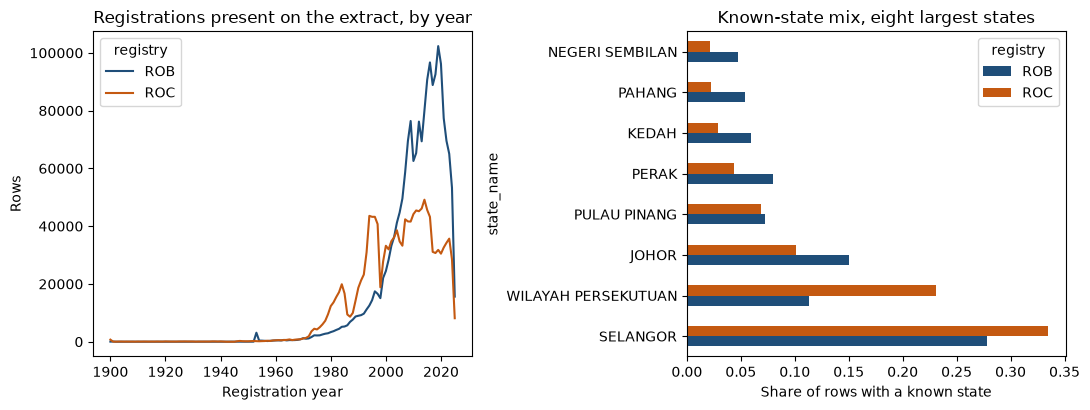

In [6]:
year_counts = (
    registry.dropna(subset=["registration_year"])
    .groupby(["registration_year", "registry"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
# A trailing partial year is still on the file; the plot keeps it and the
# caption treats the last year as incomplete rather than as a collapse.
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
year_counts.plot(ax=axes[0], color=["#1f4e79", "#c45911"])
axes[0].set_title("Registrations present on the extract, by year")
axes[0].set_xlabel("Registration year")
axes[0].set_ylabel("Rows")

known_only_share = (
    known_state.groupby("registry")["state_name"]
    .value_counts(normalize=True)
    .rename("share")
    .reset_index()
)
top_states = (
    known_state["state_name"].value_counts().head(8).index
)
top_share = known_only_share.loc[known_only_share["state_name"].isin(top_states)]
pivot = top_share.pivot(index="state_name", columns="registry", values="share").fillna(0)
pivot = pivot.loc[top_states]
pivot.plot(kind="barh", ax=axes[1], color=["#1f4e79", "#c45911"])
axes[1].set_title("Known-state mix, eight largest states")
axes[1].set_xlabel("Share of rows with a known state")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "05_registry_formation_landscape.png", dpi=140)
plt.show()
